In [7]:

from pathlib import Path

import mne
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score


# ---------------------------------------------------------
# 1. DATASET LOCATION
# ---------------------------------------------------------

DATA_ROOT = Path(
    r"C:\Users\Fafou\Desktop\Postdoc_UBC\code\EEG_project"
    r"\project1_openneuro\data\ds003061"
)

channels = ["Fz", "Cz", "Pz"]

X_parts = []
y_parts = []
groups_parts = []


# ---------------------------------------------------------
# 2. LOAD ALL SUBJECTS AND RUNS
# ---------------------------------------------------------

for subject_path in sorted(DATA_ROOT.glob("sub-*")):

    subject = subject_path.name
    print("Processing:", subject)

    eeg_files = sorted(
        (subject_path / "eeg").glob("*_eeg.set")
    )

    for eeg_file in eeg_files:

        # Load EEG
        raw = mne.io.read_raw_eeglab(
            eeg_file,
            preload=True,
            verbose=False
        )

        # Identify auxiliary channels so they are excluded
        # from EEG referencing and filtering.
        aux_channels = [
            ch for ch in raw.ch_names
            if ch.startswith("EXG") or ch in {
                "GSR1", "GSR2", "Erg1", "Erg2",
                "Resp", "Plet", "Temp"
            }
        ]

        raw.set_channel_types({
            ch: "misc" for ch in aux_channels
        })

        # Basic preprocessing
        raw.set_eeg_reference("average", verbose=False)

        raw.filter(
            l_freq=1.0,
            h_freq=None,
            picks="eeg",
            verbose=False
        )

        # Read stimulus events
        events, event_id = mne.events_from_annotations(
            raw,
            verbose=False
        )

        # Identify standard and oddball codes in this run
        standard_code = event_id["standard"]

        oddball_codes = [
            event_id[name]
            for name in ["oddball", "oddball_with_reponse"]
            if name in event_id
        ]

        if not oddball_codes:
            raise ValueError(
                f"No oddball events in {eeg_file.name}"
            )

        # Select and normalize stimulus events
        standard_mask = events[:, 2] == standard_code
        oddball_mask = np.isin(events[:, 2], oddball_codes)

        selected_mask = standard_mask | oddball_mask
        selected_events = events[selected_mask].copy()

        # Standard = 1, Oddball = 2
        selected_events[:, 2] = np.where(
            standard_mask[selected_mask], 1, 2
        )

        # Create individual EEG epochs
        epochs = mne.Epochs(
            raw,
            selected_events,
            event_id={"standard": 1, "oddball": 2},
            tmin=-0.2,
            tmax=0.8,
            baseline=(-0.2, 0),
            picks=channels,
            preload=True,
            verbose=False
        )

        # Extract mean amplitude at Fz, Cz, Pz
        # between 250 and 500 ms
        features = (
            epochs.get_data(tmin=0.25, tmax=0.50)
            .mean(axis=2) * 1e6
        )

        # Create classification labels
        # 0 = standard, 1 = oddball
        labels = (epochs.events[:, 2] == 2).astype(int)

        # Store features, labels and subject identities
        X_parts.append(features)
        y_parts.append(labels)
        groups_parts.append(
            np.repeat(subject, len(labels))
        )



Processing: sub-001


C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) GSR1, GSR2 has changed from S to NA.
  raw.set_channel_types({
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) Resp, Temp has changed from V to NA.
  raw.set_channel_types({
C:\Users\F

Processing: sub-002


C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) GSR1, GSR2 has changed from S to NA.
  raw.set_channel_types({
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) Resp, Temp has changed from V to NA.
  raw.set_channel_types({
C:\Users\F

Processing: sub-003


...

C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) GSR1, GSR2 has changed from S to NA.
  raw.set_channel_types({
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) Resp, Temp has changed from V to NA.
  raw.set_channel_types({
C:\Users\F

Processing: sub-012


C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) GSR1, GSR2 has changed from S to NA.
  raw.set_channel_types({
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) Resp, Temp has changed from V to NA.
  raw.set_channel_types({
C:\Users\F

Processing: sub-013


C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:46: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) GSR1, GSR2 has changed from S to NA.
  raw.set_channel_types({
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\978295877.py:62: RuntimeWarning: The unit for channel(s) Resp, Temp has changed from V to NA.
  raw.set_channel_types({
C:\Users\F

In [ ]:

# ---------------------------------------------------------
# 3. COMBINE ALL SUBJECTS
# ---------------------------------------------------------

X = np.vstack(X_parts)
y = np.concatenate(y_parts)
groups = np.concatenate(groups_parts)

print("\nTotal trials:", len(y))
print("Subjects:", len(np.unique(groups)))
print("Feature matrix:", X.shape)


# ---------------------------------------------------------
# 4. LEAVE-ONE-SUBJECT-OUT CROSS-VALIDATION
# ---------------------------------------------------------

logo = LeaveOneGroupOut()

results = []

for train_idx, test_idx in logo.split(X, y, groups):

    test_subject = groups[test_idx][0]

    # Create a new independent model for each fold
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000
        )
    )

    # Train on the other 12 subjects
    model.fit(X[train_idx], y[train_idx])

    # Predict trials from the held-out subject
    y_pred = model.predict(X[test_idx])
    y_prob = model.predict_proba(X[test_idx])[:, 1]

    # Evaluate performance
    balanced_acc = balanced_accuracy_score(
        y[test_idx], y_pred
    )

    auc = roc_auc_score(
        y[test_idx], y_prob
    )

    results.append({
        "subject": test_subject,
        "n_trials": len(test_idx),
        "balanced_accuracy": balanced_acc,
        "roc_auc": auc
    })



In [ ]:

# ---------------------------------------------------------
# 5. DISPLAY RESULTS
# ---------------------------------------------------------

loso_results = pd.DataFrame(results)

display(loso_results.round(3))

print("\nLOSO mean performance:")
print(
    "Balanced accuracy:",
    round(loso_results["balanced_accuracy"].mean(), 3)
)
print(
    "ROC-AUC:",
    round(loso_results["roc_auc"].mean(), 3)
)

print("\nStandard deviation:")
print(
    loso_results[["balanced_accuracy", "roc_auc"]]
    .std().round(3)
)


,subject,n_trials,balanced_accuracy,roc_auc,n_standard,n_oddball
0,sub-001,1905,0.669,0.738,1571,334
1,sub-002,1884,0.612,0.648,1550,334
2,sub-003,1877,0.628,0.660,1541,336
3,sub-004,1901,0.516,0.520,1568,333
4,sub-005,1892,0.559,0.587,1560,332
5,sub-006,1932,0.723,0.910,1594,338
6,sub-007,1869,0.568,0.600,1533,336
7,sub-008,1856,0.579,0.602,1523,333
8,sub-009,1913,0.734,0.825,1577,336
9,sub-010,1906,0.692,0.780,1571,335


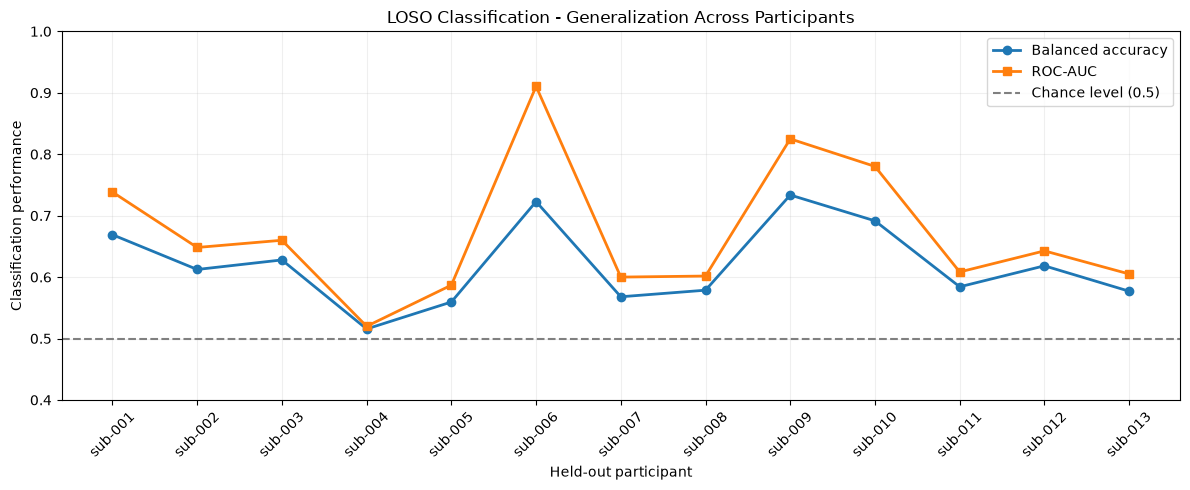

In [5]:
# ---------------------------------------------------------
# LOSO DIAGNOSTICS - PARTICIPANT VARIABILITY
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Count standard and oddball trials for each participant.
rows = []

for subject in sorted(np.unique(groups)):

    mask = groups == subject

    n_standard = np.sum(y[mask] == 0)
    n_oddball = np.sum(y[mask] == 1)

    rows.append({
        "subject": subject,
        "n_standard": n_standard,
        "n_oddball": n_oddball
    })

trial_counts = pd.DataFrame(rows)

# Combine trial counts with LOSO performance.
diagnostics = loso_results.merge(
    trial_counts,
    on="subject",
    validate="one_to_one"
)

display(diagnostics.round(3))


# ---------------------------------------------------------
# VISUALIZE CLASSIFIER GENERALIZATION
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    diagnostics["subject"],
    diagnostics["balanced_accuracy"],
    marker="o",
    linewidth=2,
    label="Balanced accuracy"
)

ax.plot(
    diagnostics["subject"],
    diagnostics["roc_auc"],
    marker="s",
    linewidth=2,
    label="ROC-AUC"
)

# Chance-level reference
ax.axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="Chance level (0.5)"
)

ax.set_xlabel("Held-out participant")
ax.set_ylabel("Classification performance")
ax.set_title("LOSO Classification - Generalization Across Participants")

ax.set_ylim(0.4, 1.0)
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Processing: sub-001


C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:52: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:52: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:73: RuntimeWarning: The unit for channel(s) GSR1, GSR2 has changed from S to NA.
  raw.set_channel_types({
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:73: RuntimeWarning: The unit for channel(s) Resp, Temp has changed from V to NA.
  raw.set_channel_types({


Scalp EEG channels: 64


C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:52: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:52: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:73: RuntimeWarning: The unit for channel(s) GSR1, GSR2 has changed from S to NA.
  raw.set_channel_types({
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:73: RuntimeWarning: The unit for channel(s) Resp, Temp has changed from V to NA.
  raw.set_channel_types({
C:\Users\Fafou

Processing: sub-002


...

Processing: sub-013


C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:52: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:52: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:73: RuntimeWarning: The unit for channel(s) GSR1, GSR2 has changed from S to NA.
  raw.set_channel_types({
C:\Users\Fafou\AppData\Local\Temp\ipykernel_20936\94316637.py:73: RuntimeWarning: The unit for channel(s) Resp, Temp has changed from V to NA.
  raw.set_channel_types({
C:\Users\Fafou


3-channel matrix: (24083, 3)
64-channel matrix: (24083, 64)
Participants: 13


,subject,BA_3ch,AUC_3ch,BA_64ch,AUC_64ch,AUC_improvement,BA_improvement
0,sub-001,0.669,0.738,0.751,0.843,0.105,0.082
1,sub-002,0.612,0.648,0.604,0.612,-0.036,-0.009
2,sub-003,0.628,0.660,0.632,0.684,0.024,0.005
3,sub-004,0.516,0.520,0.532,0.547,0.027,0.016
4,sub-005,0.559,0.587,0.610,0.663,0.077,0.051
5,sub-006,0.723,0.910,0.755,0.911,0.001,0.033
6,sub-007,0.568,0.600,0.601,0.636,0.036,0.033
7,sub-008,0.579,0.602,0.595,0.612,0.010,0.016
8,sub-009,0.734,0.825,0.762,0.885,0.060,0.029
9,sub-010,0.692,0.780,0.750,0.833,0.053,0.059



MEAN PERFORMANCE
BA_3ch      0.620
BA_64ch     0.654
AUC_3ch     0.671
AUC_64ch    0.710
dtype: float64

MEAN IMPROVEMENT (64 - 3)
BA_improvement     0.034
AUC_improvement    0.039
dtype: float64


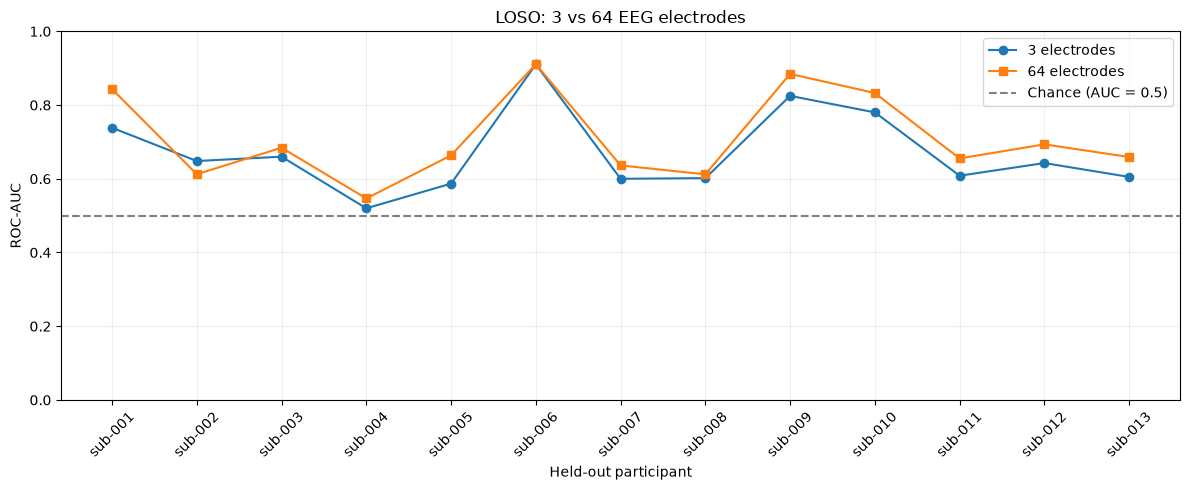

In [6]:

# ============================================================
# EXPERIMENT 2 - 3 CHANNELS VS ALL 64 EEG CHANNELS
# ============================================================

from pathlib import Path

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score


# ------------------------------------------------------------
# 1. DATASET LOCATION
# ------------------------------------------------------------

DATA_ROOT = Path(
    r"C:\Users\Fafou\Desktop\Postdoc_UBC\code\EEG_project"
    r"\project1_openneuro\data\ds003061"
)

channels_3 = ["Fz", "Cz", "Pz"]

X_parts = []
y_parts = []
groups_parts = []

eeg_channels = None


# ------------------------------------------------------------
# 2. PROCESS ALL PARTICIPANTS AND RUNS
# ------------------------------------------------------------

for subject_path in sorted(DATA_ROOT.glob("sub-*")):

    subject = subject_path.name
    print("Processing:", subject)

    eeg_files = sorted(
        (subject_path / "eeg").glob("*_eeg.set")
    )

    for eeg_file in eeg_files:

        raw = mne.io.read_raw_eeglab(
            eeg_file,
            preload=True,
            verbose=False
        )

        # The inspected recordings have 64 scalp channels,
        # followed by auxiliary channels.
        current_channels = raw.ch_names[:64]

        if eeg_channels is None:
            eeg_channels = current_channels.copy()
            print("Scalp EEG channels:", len(eeg_channels))

        # Ensure all recordings contain the same electrodes.
        if set(current_channels) != set(eeg_channels):
            raise ValueError(
                f"Channel mismatch in {eeg_file.name}"
            )

        # Exclude auxiliary channels from EEG referencing.
        raw.set_channel_types({
            ch: "misc" for ch in raw.ch_names
            if ch not in eeg_channels
        })

        # Basic preprocessing
        raw.set_eeg_reference(
            "average",
            verbose=False
        )

        raw.filter(
            l_freq=1.0,
            h_freq=None,
            picks="eeg",
            verbose=False
        )

        # Extract event markers
        events, event_id = mne.events_from_annotations(
            raw,
            verbose=False
        )

        # Identify standard and oddball event codes
        standard_code = event_id["standard"]

        oddball_codes = [
            event_id[name]
            for name in ["oddball", "oddball_with_reponse"]
            if name in event_id
        ]

        if not oddball_codes:
            raise ValueError(
                f"No oddballs in {eeg_file.name}"
            )

        # Select standard and oddball events
        standard_mask = events[:, 2] == standard_code
        oddball_mask = np.isin(
            events[:, 2],
            oddball_codes
        )

        selected_mask = standard_mask | oddball_mask
        selected_events = events[selected_mask].copy()

        # Normalize event codes across recordings:
        # Standard = 1; Oddball = 2
        selected_events[:, 2] = np.where(
            standard_mask[selected_mask],
            1,
            2
        )

        # Create epochs using all 64 scalp electrodes
        epochs = mne.Epochs(
            raw,
            selected_events,
            event_id={"standard": 1, "oddball": 2},
            tmin=-0.2,
            tmax=0.8,
            baseline=(-0.2, 0),
            picks=eeg_channels,
            preload=True,
            verbose=False
        )

        # Ensure feature order is identical across runs
        epochs.reorder_channels(eeg_channels)

        # Extract mean amplitude 250-500 ms.
        # Shape: trials x 64 channels
        features = (
            epochs.get_data(
                tmin=0.25,
                tmax=0.50
            ).mean(axis=2) * 1e6
        )

        labels = (
            epochs.events[:, 2] == 2
        ).astype(int)

        X_parts.append(features)
        y_parts.append(labels)
        groups_parts.append(
            np.repeat(subject, len(labels))
        )


# ------------------------------------------------------------
# 3. BUILD FEATURE MATRICES
# ------------------------------------------------------------

X_64 = np.vstack(X_parts)
y = np.concatenate(y_parts)
groups = np.concatenate(groups_parts)

# Select Fz, Cz and Pz from the same 64-channel data
indices_3 = [
    eeg_channels.index(ch)
    for ch in channels_3
]

X_3 = X_64[:, indices_3]

print("\n3-channel matrix:", X_3.shape)
print("64-channel matrix:", X_64.shape)
print("Participants:", len(np.unique(groups)))


# ------------------------------------------------------------
# 4. COMPARE BOTH MODELS USING IDENTICAL LOSO SPLITS
# ------------------------------------------------------------

logo = LeaveOneGroupOut()
results = []

for train_idx, test_idx in logo.split(X_64, y, groups):

    subject = groups[test_idx][0]

    row = {"subject": subject}

    for name, X in [
        ("3ch", X_3),
        ("64ch", X_64)
    ]:

        # New model for every fold and feature set
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000
            )
        )

        # Train on 12 participants
        model.fit(
            X[train_idx],
            y[train_idx]
        )

        # Predict held-out participant
        predictions = model.predict(X[test_idx])
        probabilities = model.predict_proba(
            X[test_idx]
        )[:, 1]

        # Evaluate
        row[f"BA_{name}"] = balanced_accuracy_score(
            y[test_idx],
            predictions
        )

        row[f"AUC_{name}"] = roc_auc_score(
            y[test_idx],
            probabilities
        )

    results.append(row)


# ------------------------------------------------------------
# 5. COMPARE PERFORMANCE
# ------------------------------------------------------------

comparison = pd.DataFrame(results)

comparison["AUC_improvement"] = (
    comparison["AUC_64ch"]
    - comparison["AUC_3ch"]
)

comparison["BA_improvement"] = (
    comparison["BA_64ch"]
    - comparison["BA_3ch"]
)

display(comparison.round(3))

print("\nMEAN PERFORMANCE")

print(
    comparison[
        ["BA_3ch", "BA_64ch", "AUC_3ch", "AUC_64ch"]
    ].mean().round(3)
)

print("\nMEAN IMPROVEMENT (64 - 3)")

print(
    comparison[
        ["BA_improvement", "AUC_improvement"]
    ].mean().round(3)
)


# ------------------------------------------------------------
# 6. PLOT SUBJECT-WISE ROC-AUC
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    comparison["subject"],
    comparison["AUC_3ch"],
    marker="o",
    label="3 electrodes"
)

ax.plot(
    comparison["subject"],
    comparison["AUC_64ch"],
    marker="s",
    label="64 electrodes"
)

ax.axhline(
    0.5,
    linestyle="--",
    color="gray",
    label="Chance (AUC = 0.5)"
)

ax.set_xlabel("Held-out participant")
ax.set_ylabel("ROC-AUC")
ax.set_title("LOSO: 3 vs 64 EEG electrodes")
ax.set_ylim(0, 1)

ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()
